# Probabilistic FDM — Poisson方程式 (Matérnカーネル)

PDE: $-u''(x) = f(x) = \sin(2\pi x)$, $\quad u(0)=u(1)=0$

真の解: $u(x) = \frac{1}{(2\pi)^2}\sin(2\pi x)$

観測モデル: $y = H u + \varepsilon$, $\quad H = -\Delta_h$ (負の有限差分ラプラシアン)

観測ノイズ: $\varepsilon \sim \mathcal{N}(0,\, C h^{2\tau} I_{M,N})$, $\quad C, \ell, \sigma_f$ を周辺尤度で推定

In [19]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Printf
using Statistics

In [20]:
function solve_fdm(dt)
    x_all = collect(0.0:dt:18.0)
    x_int = x_all[2:end-1]
    n_int = length(x_int)
    A = SymTridiagonal(fill(2.0/dt^2, n_int), fill(-1.0/dt^2, n_int-1))
    f_vec = f_func.(x_int)
    u_int = ldiv!(factorize(A), copy(f_vec))
    return x_all, vcat(0.0, u_int, 0.0)
end

dt = 0.4
x_fdm, u_fdm = solve_fdm(dt)
err = maximum(abs.(u_fdm .- u_exact.(x_fdm)))
println("h=$(dt):  max|u_fdm - u_exact| = $(round(err, sigdigits=4))")



σf_rms  = sqrt(mean(u_fdm.^2))


h=0.4:  max|u_fdm - u_exact| = 0.01797


0.030928558807569867

## 1. Matérnカーネル

In [22]:
function matern_kernel(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = abs(x1 - x2)
    if r == 0
        return σf^2
    end
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν) / gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_matern(X1, X2; ν=1.5, ℓ=1.0, σf=1.0)
    [matern_kernel(x1, x2; ν=ν, ℓ=ℓ, σf=σf) for x1 in X1, x2 in X2]
end

kernel_matrix_matern (generic function with 1 method)

## 2. 問題設定・観測行列 H・log周辺尤度

In [4]:
# --------------------------------------------------------
# 問題設定: -u'' = f, u(0)=u(1)=0
# f(x) = sin(2πx), u_exact(x) = sin(2πx)/(2π)^2
# --------------------------------------------------------
u_exact(x) = sin(2π * x) / (2π)^2
f_func(x)  = sin(2π * x)

# --------------------------------------------------------
# 観測行列 H = -Δ_h (負の有限差分ラプラシアン)
# 行順: [bdry_0, int_1, ..., int_{N-1}, bdry_N]
# 内点行: (-u_{i-1} + 2u_i - u_{i+1}) / h^2  = -Δ_h u_i ≈ -u''_i = f_i
# → Hu = y = (0, f(x_1), ..., f(x_{N-1}), 0) と直接対応
# --------------------------------------------------------
function observation_matrix(n_total, dt)
    n_int = n_total - 2
    H = zeros(n_total, n_total)
    H[1, 1]     = 1.0
    H[end, end] = 1.0
    for i in 1:n_int
        H[i+1, i]   = -1.0 / dt^2   # -Δ_h
        H[i+1, i+1] =  2.0 / dt^2
        H[i+1, i+2] = -1.0 / dt^2
    end
    return H
end

# 観測ベクトル: y = (u(0), f(x_1), ..., f(x_{N-1}), u(1))
make_y_train(x_all) = vcat(0.0, f_func.(x_all[2:end-1]), 0.0)

# --------------------------------------------------------
# log周辺尤度: 観測ノイズ Σ = C * h^{2τ} * diag(0,1,...,1,0)
# --------------------------------------------------------
function log_marginal_matern(
    X_train, y; H, dt, ν, ℓ, σf, C, τ, jitter=1e-10
)
    n_total   = length(X_train)
    noise_var = C * dt^(2τ)
    Σ_diag    = vcat([0.0], fill(noise_var, n_total - 2), [0.0])
    Σ         = Diagonal(Σ_diag)

    K     = kernel_matrix_matern(X_train, X_train; ν=ν, ℓ=ℓ, σf=σf)
    K_obs = H * K * H' + Σ #+ jitter * I

    L       = cholesky(Hermitian(K_obs)).L
    α       = L' \ (L \ y)
    logdetK = 2sum(log.(diag(L)))

    return -0.5 * (y' * α) - 0.5 * logdetK - 0.5 * length(y) * log(2π)
end

log_marginal_matern (generic function with 1 method)

## 3. ハイパーパラメータ選択 (ℓ, σf, C をグリッドサーチ)

In [23]:
ν_fixed = 1.5
τ_fixed = 2
#dt_list = [0.4, 0.3, 0.2,  0.05]
dt_list = [0.4]

# ℓ, σf, C をグリッドサーチ
# σf のスケールは H の内点行が 1/h^2 オーダーなので
# HKH' ~ σf^2/h^4 が観測値のスケール(~1)に合うよう
# σf ~ h^2 付近を中心にグリッドを張る
#ℓ_grid = 10 .^ range(-1, 1, length=10)   # 0.1 〜 100
ℓ_grid = 10 .^ range(-1, 1, length=10)
#σf_grid = 10 .^ range(-2, 0, length=10)   # 0.01 〜 10
σf_gri = [σf_rms]
C_grid = 10 .^ range(-3, 2, length=10)  
#ℓ_grid =  [10 .^ (-1.6)]
#σf_grid = [10 .^ (-1.6)]   # 0.01 〜 100

best_params = Dict()

for dt in dt_list
    x_all   = collect(0.0:dt:18.0)
    n_total = length(x_all)
    H       = observation_matrix(n_total, dt)
    y_train = make_y_train(x_all)

    # σf のグリッドを dt に応じてスケール
    # HKH' 対角 ~ σf^2/h^4 → σf ~ h^2 が自然なスケール
    #σf_center = dt^2
    #σf_grid = σf_center .* 10 .^ range(-2, 3, length=15)

    scores = fill(-Inf, length(ℓ_grid), length(σf_grid), length(C_grid))

    for (i, ℓ) in enumerate(ℓ_grid)
        for (j, σf) in enumerate(σf_grid)
            for (k, C) in enumerate(C_grid)
                try
                    scores[i,j,k] = log_marginal_matern(
                        x_all, y_train;
                        H=H, dt=dt, ν=ν_fixed,
                        ℓ=ℓ, σf=σf, C=C, τ=τ_fixed
                    )
                catch
                    scores[i,j,k] = -Inf
                end
            end
        end
    end

    best_idx = argmax(scores)
    bI       = CartesianIndices(scores)[best_idx]
    best_ℓ   = ℓ_grid[bI[1]]
    best_σf  = σf_grid[bI[2]]
    best_C   = C_grid[bI[3]]
    best_params[dt] = (best_ℓ, best_σf, best_C)

    #snr = best_σf^2 / dt^4 / (best_C * dt^(2*τ_fixed))
    println("dt=$(dt): ℓ=$(round(best_ℓ,sigdigits=3)), ",
            "σf=$(round(best_σf,sigdigits=3)), ",
            "C=$(round(best_C,sigdigits=3)), ",
            "loglik=$(round(scores[best_idx],sigdigits=5)), ",
#            "SNR=$(round(snr,sigdigits=3))"
            )
end


dt=0.4: ℓ=0.1, σf=0.0278, C=0.001, loglik=6.5914, 


## 4. 事後分布の計算と4パネル図

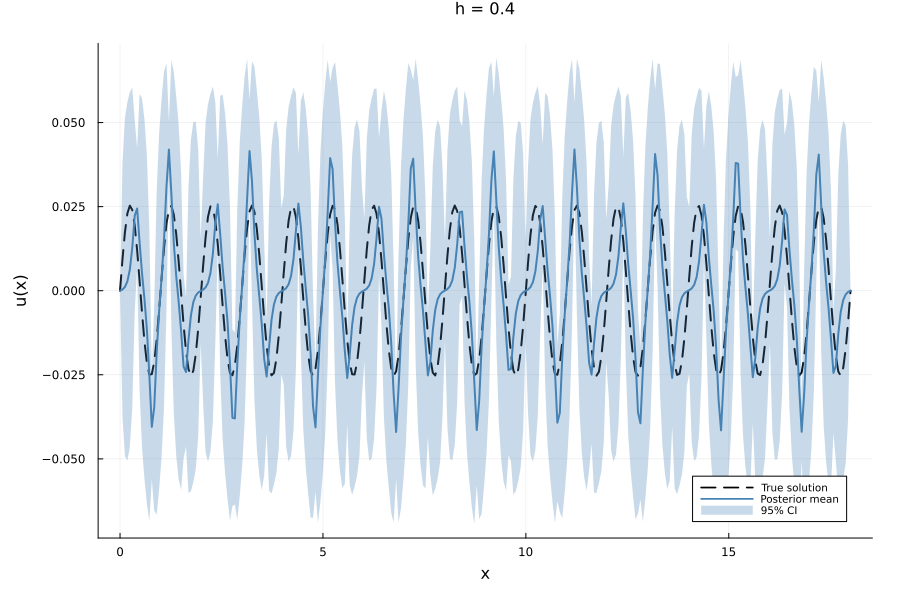

Saved: poisson_matern_4panels.png


In [24]:
function run_pfdm(dt; ν, ℓ, σf, C, τ, n_test=300)
    x_all   = collect(0.0:dt:18.0)
    n_total = length(x_all)
    H       = observation_matrix(n_total, dt)
    y_train = make_y_train(x_all)

    noise_var = C * dt^(2τ)
    Σ_diag    = vcat([0.0], fill(noise_var, n_total - 2), [0.0])
    Σ         = Diagonal(Σ_diag)

    K     = kernel_matrix_matern(x_all, x_all; ν=ν, ℓ=ℓ, σf=σf)
    K_obs = H * K * H' + Σ #+ 1e-10 * I

    X_test = collect(range(0.0, 18.0, length=n_test))
    # 事後平均: μ = k(X_test, x_all) * H' * (HKH'+Σ)^{-1} * y
    Ks     = kernel_matrix_matern(X_test, x_all; ν=ν, ℓ=ℓ, σf=σf) * H'
    Kss    = kernel_matrix_matern(X_test, X_test; ν=ν, ℓ=ℓ, σf=σf)

    K_chol   = cholesky(Hermitian(K_obs))
    μ_post   = Ks * (K_chol \ y_train)
    Σ_post   = Kss - Ks * (K_chol \ Ks')
    std_post = sqrt.(max.(diag(Σ_post), 0.0))

    return X_test, μ_post, std_post, u_exact.(X_test)
end

plots_list = []

for dt in dt_list
    best_ℓ, best_σf, best_C = best_params[dt]
    X_test, μ, σ, u_true = run_pfdm(
        dt; ν=ν_fixed, ℓ=best_ℓ, σf=best_σf, C=best_C, τ=τ_fixed
    )

    p = plot(
        X_test, u_true;
        label="True solution",
        lw=2, ls=:dash, color=:black,
        xlabel="x", ylabel="u(x)",
        title="h = $(dt)",
        titlefontsize=11, legendfontsize=7,
    )
    plot!(p, X_test, μ;
        label="Posterior mean", lw=2, color=:steelblue
    )
    plot!(p, X_test, μ .+ 1.96 .* σ;
        fillrange = μ .- 1.96 .* σ,
        fillalpha = 0.3, linealpha = 0,
        label = "95% CI", color = :steelblue
    )
    push!(plots_list, p)
end

fig = plot(
    plots_list...;
    layout = (2, 2),
    size   = (900, 600),
    margin = 5Plots.mm,
)
display(fig)
savefig(fig, "poisson_matern_4panels.png")
println("Saved: poisson_matern_4panels.png")

## 通常のFDM（比較用）

三重対角行列を直接解く標準的な有限差分法。各 h でのFDM解と最大誤差を求め，Probabilistic FDM と同じパネルに重ねてプロット。

## プロット（Probabilistic FDM ＋ 通常FDM 重ね描き）

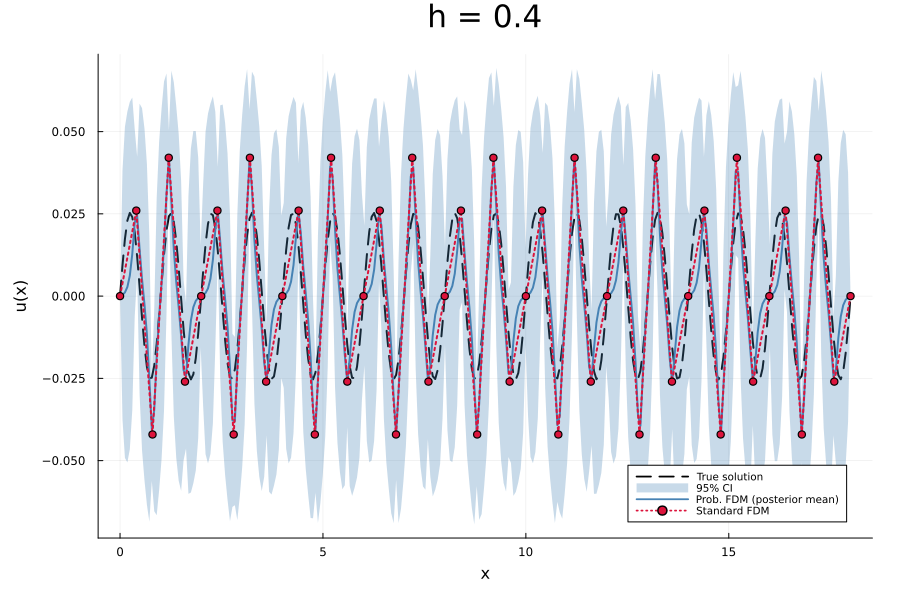

Saved: poisson_comparison_4panels.png


In [25]:
plots_list2 = []

for dt in dt_list
    best_ℓ, best_σf, best_C = best_params[dt]
    X_test, μ, σ, u_true = run_pfdm(
        dt; ν=ν_fixed, ℓ=best_ℓ, σf=best_σf, C=best_C, τ=τ_fixed
    )
    x_fdm, u_fdm = solve_fdm(dt)

    p = plot(
        X_test, u_true;
        label="True solution",
        lw=2, ls=:dash, color=:black,
        xlabel="x", ylabel="u(x)",
        title="h = $(dt)",
        titlefontsize=21, legendfontsize=7,
    )
    plot!(p, X_test, μ .+ 1.96 .* σ;
        fillrange = μ .- 1.96 .* σ,
        fillalpha = 0.3, linealpha = 0,
        label = "95% CI", color = :steelblue
    )
    plot!(p, X_test, μ;
        label="Prob. FDM (posterior mean)", lw=2, color=:steelblue
    )
    plot!(p, x_fdm, u_fdm;
        label="Standard FDM", lw=2, ls=:dot, color=:crimson,
        markershape=:circle, markersize=4
    )
    push!(plots_list2, p)
end

fig2 = plot(
    plots_list2...;
    layout = (2, 2),
    size   = (900, 600),
    margin = 5Plots.mm,
)
display(fig2)
savefig(fig2, "poisson_comparison_4panels.png")
println("Saved: poisson_comparison_4panels.png")




In [ ]:
# ============================================================
# σf を FDM 解から推定して，ℓ vs C の lml 表を表示
# ============================================================

dt = 0.4
x_all   = collect(0.0:dt:18.0)
n_total = length(x_all)
H       = observation_matrix(n_total, dt)
y_train = make_y_train(x_all)

# FDM 解から σf を推定
_, u_fdm_04 = solve_fdm(dt)
σf_max = maximum(abs.(u_fdm_04))
σf_rms = sqrt(mean(u_fdm_04.^2))
σf_std = std(u_fdm_04)
println("=== σf 推定値 (h=$(dt)) ===")
println("σf_max = $(round(σf_max, sigdigits=4))")
println("σf_rms = $(round(σf_rms, sigdigits=4))")
println("σf_std = $(round(σf_std, sigdigits=4))")

# σf_rms で固定して ℓ vs C の表
σf_fixed = σf_rms
ℓ_grid_table = 10.0 .^ range(-2, 1, length=8)
C_grid_table = vcat([0.0], 10.0 .^ range(-4, 2, length=8))

println("\n=== lml table (σf=$(round(σf_fixed,sigdigits=3)) fixed, h=$(dt)) ===")
@printf("%-12s", "ℓ \\ C")
for C in C_grid_table
    if C == 0.0
        @printf("%-11s", "0")
    else
        @printf("%-11s", round(C, sigdigits=2))
    end
end
println()
println("-"^(12 + 11*length(C_grid_table)))

best_lml = -Inf; best_l = ℓ_grid_table[1]; best_C = C_grid_table[1]

for ℓ in ℓ_grid_table
    @printf("%-12s", round(ℓ, sigdigits=2))
    for C in C_grid_table
        lml = try
            log_marginal_matern(x_all, y_train;
                H=H, dt=dt, ν=ν_fixed,
                ℓ=ℓ, σf=σf_fixed, C=C, τ=τ_fixed)
        catch
            NaN
        end
        @printf("%-11s", isnan(lml) ? "NaN" : round(lml, digits=1))
        if !isnan(lml) && lml > best_lml
            best_lml = lml; best_l = ℓ; best_C = C
        end
    end
    println()
end
println("-"^(12 + 11*length(C_grid_table)))
println("Best: ℓ=$(round(best_l,sigdigits=3)), C=$(round(best_C,sigdigits=3)), lml=$(round(best_lml,digits=2))")
